# Project links

**Github repository**
https://github.com/phkhle/IND320/tree/project2

**Streamlitt app**
https://ind320-project2.streamlit.app/


In [4]:
import pandas as pd
from NVE_API import get_nve_data
import matplotlib.pyplot as plt


# IND320 – Project 2

## Data Engineering with APIs, Apache Spark, Cassandra and MongoDB

### Project overview

This project explores a data engineering workflow using electricity related datasets from Norway.

The project includes two data sources:

1. **NVE API:** Norwegian reservoir filling levels.
2. **ENTSO-E API:** Cross-border electricity imports and exports.

The workflow uses:
- Python for API data collection
- Apache Spark for data processing
- Apache Cassandra for storing electricity transfer observations
- MongoDB Atlas for storing aggregated data
- Streamlit for interactive visualization

The project uses real observations from both the NVE API and the ENTSO-E Transparency Platform. ENTSO-E electricity transfer data for 2024–2025 has been collected and stored in Apache Cassandra using Apache Spark. The dataset contains 394,464 observations across nine Norwegian cross-border connections. Spark was used to aggregate the observations into monthly and daily totals, which were subsequently stored in MongoDB Atlas. The Streamlit dashboard retrieves these aggregated datasets for interactive visualization.

## 1. NVE API – Norwegian Reservoir Data

The Norwegian Water Resources and Energy Directorate (NVE) provides public reservoir statistics through an API.

In this section, I retrieve real reservoir data using Python and inspect the dataset before further analysis.

The API data will also be used in the Streamlit dashboard.

In [5]:
# Retrieve reservoir data from NVE API
df_nve = get_nve_data()

# Inspect the dataset
print("Dataset shape:", df_nve.shape)

display(df_nve.head())

Dataset shape: (14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837
2,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
3,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643


## 2. Exploratory Data Analysis (EDA)

Before visualizing the reservoir data, I examine the dataset's structure, time coverage, area types, and missing values.

This helps us understand the data quality and determine how the observations should be grouped.

In [6]:
# Check data types
print("Data types:")
print(df_nve.dtypes)

# Check missing values
print("\nMissing values:")
print(df_nve.isna().sum())

# Check available area types
print("\nArea types:")
print(df_nve["omrType"].value_counts())

# Check time coverage
df_nve["dato_Id"] = pd.to_datetime(df_nve["dato_Id"])

print("\nDate range:")
print("From:", df_nve["dato_Id"].min())
print("To:", df_nve["dato_Id"].max())

Data types:
dato_Id                     datetime64[ns]
omrType                             object
omrnr                                int64
iso_aar                              int64
iso_uke                              int64
fyllingsgrad                       float64
kapasitet_TWh                      float64
fylling_TWh                        float64
neste_Publiseringsdato              object
fyllingsgrad_forrige_uke           float64
endring_fyllingsgrad               float64
dtype: object

Missing values:
dato_Id                     0
omrType                     0
omrnr                       0
iso_aar                     0
iso_uke                     0
fyllingsgrad                0
kapasitet_TWh               0
fylling_TWh                 0
neste_Publiseringsdato      0
fyllingsgrad_forrige_uke    0
endring_fyllingsgrad        0
dtype: int64

Area types:
omrType
EL      8290
VASS    4974
NO      1658
Name: count, dtype: int64

Date range:
From: 1995-01-08 00:00:00
To: 2026-10-11 0

In [7]:
# Number of unique areas within each area type
area_summary = (
    df_nve.groupby("omrType")["omrnr"]
    .nunique()
    .reset_index(name="number_of_areas")
)

display(area_summary)

# Show area numbers within each type
for area_type, group in df_nve.groupby("omrType"):
    print(f"\nArea type: {area_type}")
    print("Area numbers:", sorted(group["omrnr"].unique()))

,omrType,number_of_areas
0,EL,5
1,NO,1
2,VASS,3



Area type: EL
Area numbers: [1, 2, 3, 4, 5]

Area type: NO
Area numbers: [0]

Area type: VASS
Area numbers: [1, 2, 3]


## 3. Reservoir Filling Levels Over Time

I visualize the development of reservoir filling levels across Norwegian electricity price areas (EL), as an example.

Each line represents one area. This allows us to compare seasonal patterns and differences between regions.

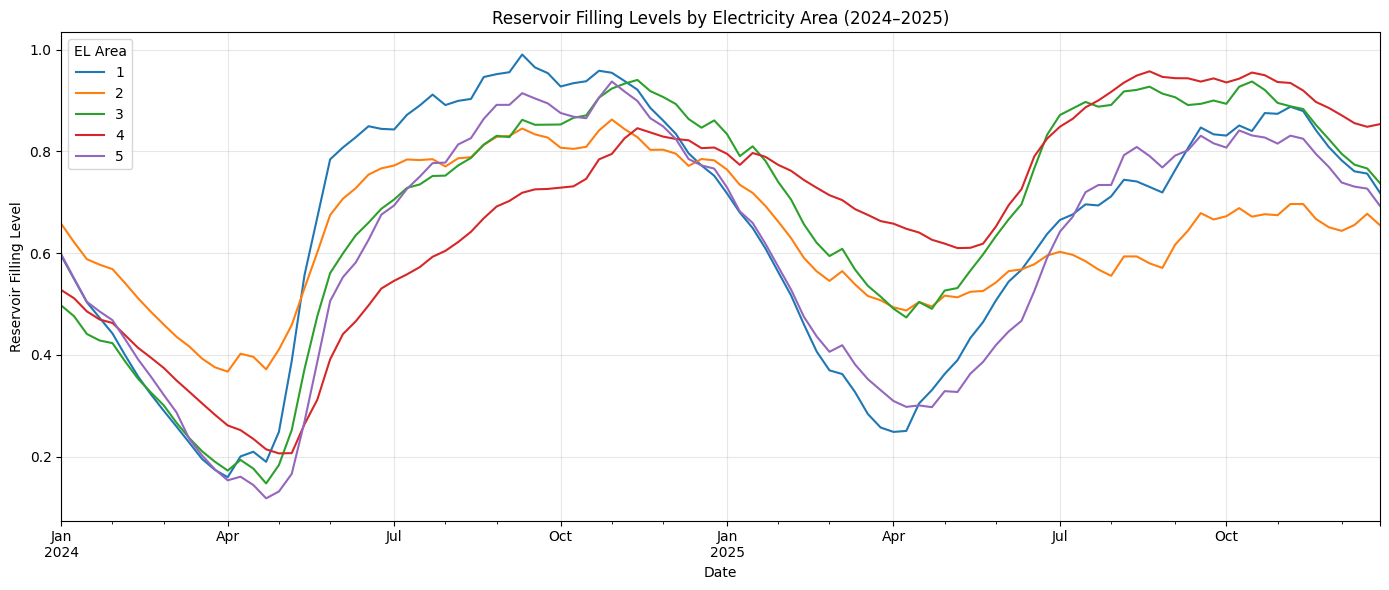

In [8]:

# Select EL areas
df_el = df_nve[df_nve["omrType"] == "EL"].copy()

# Focus on the last two complete calendar years
df_el = df_el[
    (df_el["dato_Id"] >= "2024-01-01") &
    (df_el["dato_Id"] < "2026-01-01")
]

# Pivot: one column per area
df_plot = df_el.pivot_table(
    index="dato_Id",
    columns="omrnr",
    values="fyllingsgrad",
    aggfunc="mean"
)

# Plot
ax = df_plot.plot(figsize=(14, 6))

ax.set_title("Reservoir Filling Levels by Electricity Area (2024–2025)")
ax.set_xlabel("Date")
ax.set_ylabel("Reservoir Filling Level")
ax.legend(title="EL Area")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Apache Spark and Cassandra

Apache Spark is used for distributed data processing, while Apache Cassandra provides storage for electricity transfer observations.

In this project, both services run in Docker containers. The Spark Cassandra Connector enables Spark to write data to and read data from Cassandra.

### 4.1 Data collection and storage

Electricity transfer data was collected from the ENTSO-E Transparency Platform for the period January 2024 to December 2025. The dataset covers nine cross-border electricity connections involving Norway and contains 394,464 observations.

Apache Cassandra was used to store the collected observations in the ind320.entsoe_real table. Cassandra was run locally in a Docker container.

In [9]:
# Spark and Cassandra integration
# Executed in Docker using ENTSOE_Spark.py

spark_command = """
docker cp ENTSOE_Spark.py spark-cassandra:/tmp/ENTSOE_Spark.py

docker exec spark-cassandra /opt/spark/bin/spark-submit \
    --conf spark.jars.ivy=/tmp/ivy2 \
    --packages com.datastax.spark:spark-cassandra-connector_2.12:3.5.1 \
    --conf spark.cassandra.connection.host=cassandra-db \
    /tmp/ENTSOE_Spark.py
"""

print(spark_command)


docker cp ENTSOE_Spark.py spark-cassandra:/tmp/ENTSOE_Spark.py

docker exec spark-cassandra /opt/spark/bin/spark-submit     --conf spark.jars.ivy=/tmp/ivy2     --packages com.datastax.spark:spark-cassandra-connector_2.12:3.5.1     --conf spark.cassandra.connection.host=cassandra-db     /tmp/ENTSOE_Spark.py



### 4.2 Data processing with Apache Spark

Apache Spark was used to read and process the ENTSO-E observations stored in Cassandra.

The processing included:

- Reading the observations from Cassandra using the Spark Cassandra Connector.

- Handling timestamps and converting energy values to MWh.

- Aggregating electricity imports and exports by connection and time period.

- Preparing monthly and daily datasets for visualization.

### 4.3 Export to MongoDB Atlas

The aggregated datasets were exported from Spark and stored in MongoDB Atlas.

Two collections were prepared:

- entsoe_monthly: 216 documents containing monthly import and export totals.

- entsoe_daily: 6,579 documents containing daily import and export totals.

MongoDB Atlas provides the data source for the Streamlit dashboard, allowing the application to visualize aggregated electricity transfers without querying Cassandra directly.

### 4.4 Data pipeline

The complete data pipeline is:

ENTSO-E API → Apache Cassandra → Apache Spark → MongoDB Atlas → Streamlit

This architecture separates raw data storage, distributed data processing, and interactive visualization.

## 5. ENTSO-E Data Visualization

### 5.1 Annual Electricity Imports and Exports

Visualizes annual electricity imports and exports between Norway and a selected neighboring country using aggregated data retrieved from MongoDB Atlas.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from MongoDB_API import get_entsoe_monthly_data

# Load monthly aggregated ENTSO-E data from MongoDB
df_monthly = get_entsoe_monthly_data()

print("Number of records:", len(df_monthly))
print("Columns:", df_monthly.columns.tolist())

display(df_monthly.head())

Number of records: 216
Columns: ['connection', 'month', 'is_test_data', 'total_export_mwh', 'total_import_mwh']


,connection,month,is_test_data,total_export_mwh,total_import_mwh
0,NO2-NL,2024-01,False,131180.7025,119935.2975
1,NO2-NL,2025-01,False,391696.6625,12733.5775
2,NO2-NL,2024-05,False,321748.0300,45162.8625
3,NO2-NL,2024-06,False,288637.5150,54663.1275
4,NO2-NL,2024-07,False,283767.6275,53718.1275


Create cake diagram

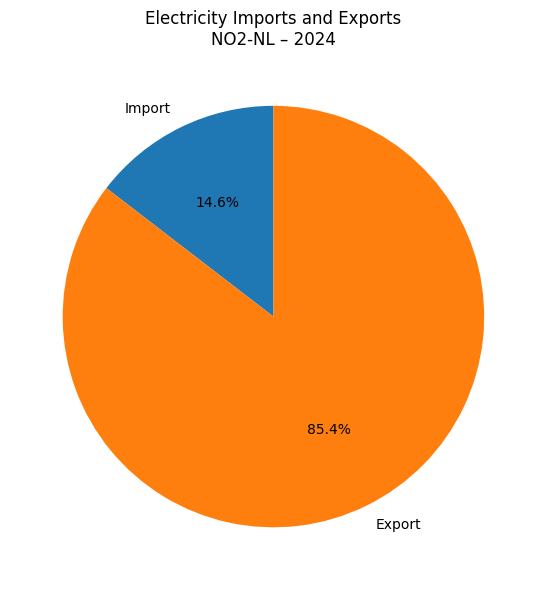

Import: 596,107.94 MWh
Export: 3,496,670.36 MWh


In [12]:
# Select connection and year
selected_connection = "NO2-NL"
selected_year = 2024

# Filter monthly data
df_selected = df_monthly[
    (df_monthly["connection"] == selected_connection)
    & (df_monthly["month"].str.startswith(str(selected_year)))
]

# Calculate annual totals
total_import = df_selected["total_import_mwh"].sum()
total_export = df_selected["total_export_mwh"].sum()

# Plot annual electricity transfers
fig, ax = plt.subplots(figsize=(7, 6))

ax.pie(
    [total_import, total_export],
    labels=["Import", "Export"],
    autopct="%1.1f%%",
    startangle=90,
)

ax.set_title(
    f"Electricity Imports and Exports\n"
    f"{selected_connection} – {selected_year}"
)

plt.tight_layout()
plt.show()

print(f"Import: {total_import:,.2f} MWh")
print(f"Export: {total_export:,.2f} MWh")

### 5.2 Daily Electricity Imports and Exports
Visualizes daily electricity imports and exports
for a selected connection during the first month of the selected year.

Daily aggregated data is retrieved from MongoDB Atlas.

In [13]:
from MongoDB_API import get_entsoe_daily_data

# Load daily data from MongoDB
df_daily = get_entsoe_daily_data()

print("Number of records:", len(df_daily))
print("Columns:", df_daily.columns.tolist())

display(df_daily.head())

Number of records: 6579
Columns: ['date', 'connection', 'is_test_data', 'total_export_mwh', 'total_import_mwh']


,date,connection,is_test_data,total_export_mwh,total_import_mwh
0,2024-01-01,NO1-SE3,False,0.00,36698.82
1,2024-01-02,NO1-SE3,False,27.83,23781.26
2,2024-01-03,NO1-SE3,False,35.19,29509.18
3,2024-01-10,NO1-SE3,False,546.75,8202.73
4,2024-01-18,NO1-SE3,False,14251.35,1690.86


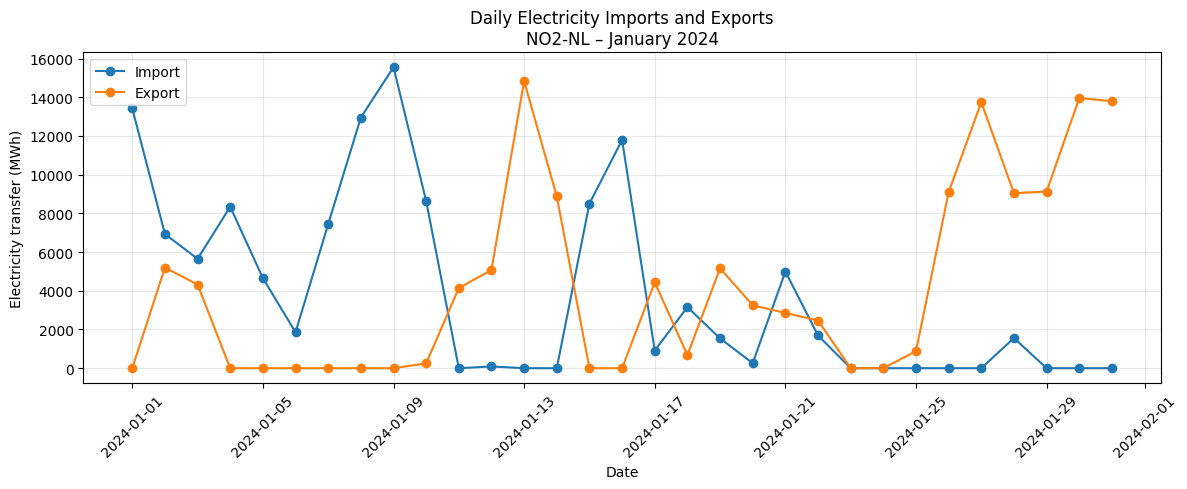

Number of days: 31


In [14]:
# Use the same connection and year as the pie chart
selected_connection = "NO2-NL"
selected_year = 2024
selected_month = 1

# Convert dates to datetime
df_daily["date"] = pd.to_datetime(df_daily["date"])

# Filter by connection, year and month
df_selected_daily = df_daily[
    (df_daily["connection"] == selected_connection)
    & (df_daily["date"].dt.year == selected_year)
    & (df_daily["date"].dt.month == selected_month)
].copy()

# Sort chronologically
df_selected_daily = df_selected_daily.sort_values("date")

# Plot daily import and export
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df_selected_daily["date"],
    df_selected_daily["total_import_mwh"],
    marker="o",
    label="Import",
)

ax.plot(
    df_selected_daily["date"],
    df_selected_daily["total_export_mwh"],
    marker="o",
    label="Export",
)

ax.set_title(
    f"Daily Electricity Imports and Exports\n"
    f"{selected_connection} – January {selected_year}"
)
ax.set_xlabel("Date")
ax.set_ylabel("Electricity transfer (MWh)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Number of days:", len(df_selected_daily))

## 6. Project log

The project was developed in two main parts: retrieving and visualizing Norwegian reservoir data from NVE, and processing cross-border electricity transfer data from ENTSO-E.

For the NVE part, I connected to the NVE API using Python and explored the returned dataset with pandas. I examined data types, missing values and geographical areas before creating time-series visualizations. I then developed Streamlit pages that allow users to select area types, time intervals and measurements.

For the ENTSO-E part, I collected electricity transfer observations for nine Norwegian cross-border connections covering 2024 and 2025. The observations were stored in Apache Cassandra, running in Docker. I used Apache Spark to read and process the data, calculate monthly and daily import and export totals, and prepare datasets for MongoDB Atlas.

The processed datasets were uploaded to MongoDB Atlas and retrieved through Python functions. I used these data to create an annual pie chart and a daily line chart in Jupyter Notebook. I also developed a Streamlit page with interactive connection, year and month selections.

### Challenges and solutions

- Configuring communication between Docker containers running Cassandra and Spark. I had to ensure that the containers used compatible versions and could communicate through the Docker network.

- Processing a relatively large ENTSO-E dataset. Spark and Cassandra initially encountered write timeouts, so I investigated the errors and adjusted the processing workflow.

- Deploying Streamlit. The application could not find the MongoDB connection string. I resolved this by configuring Streamlit Secrets and updating the Python connection function. I also looked at the MongoDB Atlas network access settings when the deployed application could not connect to the database

### Use of AI

I used AI as a learning and debugging assistant throughout the entire project. It helped me understand technical concepts, troubleshoot Python and Docker errors, structure functions and organize the notebook documentation.

I ran the code, inspected the results and adjusted the implementation when necessary. 
AI was particularly useful for breaking complex integration tasks into smaller, manageable steps.